# Adaptive conformal inference

ACI is the simplest of the online methods. Where split conformal fixes the
coverage level once and holds it, ACI adjusts the level it requests as
observations arrive — widening after a miss, tightening after a hit — which is
what lets it keep long-run coverage on a series whose errors are drifting.

## What it does

ACI keeps a *time-varying* target `alpha_t`, one per `(series, horizon)` cell,
initialised at `alpha`. After each observation it checks whether the truth fell
inside the interval and nudges the target:

```
alpha_{t+1} = alpha_t + gamma * (alpha - 1{miss})
```

A miss makes the bracket `(alpha - 1)` negative, so `alpha_t` shrinks and the
next interval is **wider**. A hit adds `gamma * alpha`, so `alpha_t` creeps up
and the interval tightens. The interval itself is still an ordinary split
conformal interval — just taken at `alpha_t` instead of `alpha`.

This is a control loop, and it has the property a control loop should: the
long-run empirical coverage converges to `1 - alpha` **whatever the data does**,
with no exchangeability assumption at all. What it gives up is any finite-sample
promise about a single step — `alpha_t` can wander far from `alpha` while it
chases a shift.

`gamma` is the learning rate. Gibbs and Candès recommend `[0.005, 0.05]`; a
field validator warns above `0.1`. Small `gamma` adapts slowly and stays near split
conformal; large `gamma` reacts fast and oscillates.

::: {.callout-warning}
## `gamma` too large degenerates, it does not merely wobble

Nothing stops `alpha_t` from being driven to zero or below by a run of misses.
At `alpha_t <= 0` the requested quantile sits beyond the largest calibration
score and the interval becomes infinitely wide — technically 100% covering, and
useless. On this 48-month stream `gamma = 0.2` does exactly that within a few
steps. Stay inside the recommended range; that is what the constructor warning
above `0.1` is for.
:::

## Worked example

Adaptation only shows up over many steps, so this page forecasts one month ahead
and streams the last four years through the method one observation at a time —
`predict`, then `update` with what actually happened. `calibrate_cv` returns a
fitted object, and `update` advances that object's state in place.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsforecast import StatsForecast
from statsforecast.models import AutoETS

from conformalforecast import AdaptiveConformalInference, SplitConformal
from conformalforecast.adapters import StatsForecastAdapter
from conformalforecast.diagnostics import aci_state

SEASON, ALPHA = 12, 0.1
TRAIN_END = 96  # stream the remaining 48 months

df = pd.read_csv("nbs/data/air_passengers.csv", parse_dates=["ds"])
panel = df["y"].to_numpy()[None, :]
train_df = df.iloc[:TRAIN_END].reset_index(drop=True)

sf = StatsForecast(models=[AutoETS(season_length=SEASON)], freq="MS", n_jobs=1)
sf.fit(train_df)
forecaster = StatsForecastAdapter(
    sf=sf, train_df=train_df, horizon=1, freq="MS", model_name="AutoETS"
)


def stream(fitted, *, online=True):
    """Roll one step at a time, recording the interval and whether it covered."""
    lower, upper, covered, alpha_t = [], [], [], []
    for t in range(TRAIN_END, panel.shape[1]):
        prediction = fitted.predict(panel[:, :t])
        truth = panel[:, t : t + 1][:, None, :]  # (n_series, 1, horizon)
        lo, hi = prediction.interval[0, 0, 0]
        lower.append(lo)
        upper.append(hi)
        covered.append(lo <= panel[0, t] <= hi)
        if online:
            alpha_t.append(float(fitted.alpha_t_[0, 0]))
            fitted.update(prediction.point, truth)
    return {
        "lower": np.array(lower),
        "upper": np.array(upper),
        "covered": np.array(covered),
        "alpha_t": np.array(alpha_t),
    }

Three learning rates, plus split conformal as the `gamma = 0` reference. Each one
is calibrated on the same 48 cross-validation windows before the stream starts.

In [ ]:
GAMMAS = [0.005, 0.02, 0.05]

runs = {}
for gamma in GAMMAS:
    method = AdaptiveConformalInference(alpha=ALPHA, gamma=gamma)
    fitted = method.calibrate_cv(forecaster, n_windows=48)
    runs[f"ACI gamma={gamma}"] = stream(fitted)
    if gamma == 0.05:
        tuned = fitted

split = SplitConformal(alpha=ALPHA).calibrate_cv(forecaster, n_windows=48)
runs["split conformal"] = stream(split, online=False)

for name, run in runs.items():
    width = (run["upper"] - run["lower"]).mean()
    print(f"{name:20s} coverage {run['covered'].mean():6.1%}   mean width {width:6.1f}")

ACI gamma=0.005      coverage  87.5%   mean width   78.0
ACI gamma=0.02       coverage  93.8%   mean width   87.2
ACI gamma=0.05       coverage  89.6%   mean width   88.4
split conformal      coverage  85.4%   mean width   74.7


## What `alpha_t` did

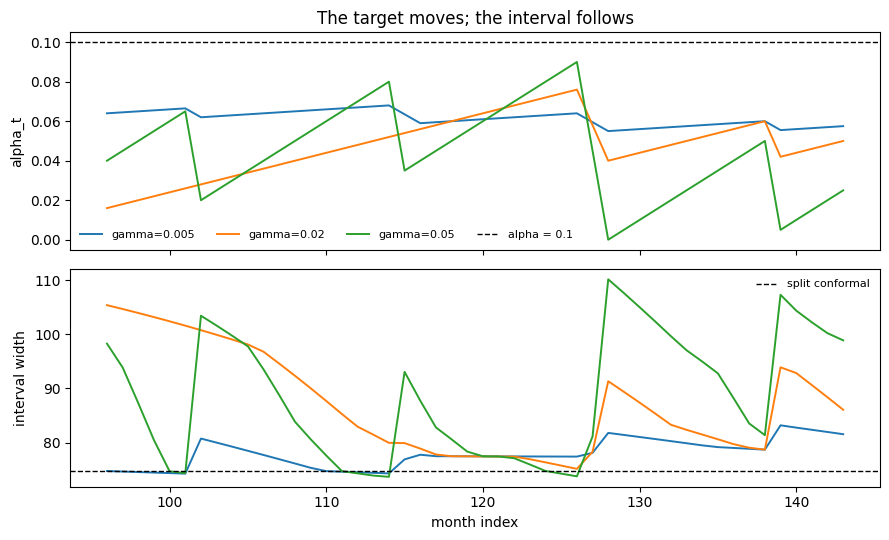

In [ ]:
months = np.arange(TRAIN_END, panel.shape[1])

fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True)

for i, gamma in enumerate(GAMMAS):
    run = runs[f"ACI gamma={gamma}"]
    top.plot(months, run["alpha_t"], color=f"C{i}", lw=1.4, label=f"gamma={gamma}")
    bottom.plot(months, run["upper"] - run["lower"], color=f"C{i}", lw=1.4)

top.axhline(ALPHA, color="k", lw=1, ls="--", label="alpha = 0.1")
top.set_ylabel("alpha_t")
top.set_title("The target moves; the interval follows")
top.legend(fontsize=8, frameon=False, ncol=4)

split_width = (runs["split conformal"]["upper"] - runs["split conformal"]["lower"]).mean()
bottom.axhline(split_width, color="k", lw=1, ls="--", label="split conformal")
bottom.set_ylabel("interval width")
bottom.set_xlabel("month index")
bottom.legend(fontsize=8, frameon=False)
fig.tight_layout()

None of the three starts at `alpha = 0.1`, because `calibrate_cv` already rolled
`alpha_t` forward through its 48 windows — an online method adapts during
calibration too, not only during the stream.

Read the top panel as the controller's state. Every miss knocks `alpha_t` down by
`gamma * (1 - alpha)` — a visible cliff — and every hit lets it drift back up by
`gamma * alpha`, a tenth as fast. That asymmetry is the algorithm: it is
expensive to miss and cheap to be a little conservative.

`gamma = 0.005` barely leaves the split-conformal line over 48 months;
`gamma = 0.05` reacts within a step or two. The bottom panel is the consequence:
split conformal holds one width for four years, while the adaptive runs breathe.

Which rate is right depends on how fast your process actually moves, and you do
not know that in advance. [AgACI](./agaci.html) exists so you do not have to guess.

In [ ]:
state = aci_state(tuned)
print(f"gamma                {state['gamma']}")
print(f"observations seen    {state['n_observations']}")
print(f"final alpha_t        {state['alpha_t'][0, 0]:.4f}")
print(f"drift from alpha     {state['alpha_t_minus_alpha'][0, 0]:+.4f}")

gamma                0.05
observations seen    96
final alpha_t        0.0300
drift from alpha     -0.0700


`n_observations` counts the calibration windows *and* the streamed updates —
online state does not reset when you stop calibrating and start predicting.

## When not to use it

- **You cannot feed truths back.** ACI without `update` is split conformal with
  extra steps. If your pipeline never learns what actually happened, use
  [split conformal](./split.html) or [CQR](./cqr.html) and be honest about it.
- **You do not want to tune `gamma`.** Use [AgACI](./agaci.html), which runs a panel of
  learning rates and aggregates them online.
- **Your problem is width, not level.** ACI moves the coverage target; it does
  not change the *shape* of the band. If the complaint is "too wide in calm
  periods, too narrow in volatile ones", that is [SPCI](./spci.html).

## References

I. Gibbs and E. Candès, “Adaptive Conformal Inference Under Distribution Shift,” arXiv.org, 2021. https://arxiv.org/abs/2106.00170.

## Next

- [AgACI](./agaci.html) — ACI without choosing `gamma`.
- [NexCP](./nexcp.html) — the other answer to drift: down-weight stale residuals.
- [Online updating](../capabilities/online-updating.html) — the `predict`/`update`
  loop in general.